# Timing & Counting Individual Analysis

I recommend the [Whirlwind Tour of Python](https://jakevdp.github.io/WhirlwindTourOfPython/) and the [Python Data Science Handbook](https://jakevdp.github.io/PythonDataScienceHandbook/) both by Jake VanderPlas.

## Part 1: Looking at the inverse-square law

You may want to look at the example code presented in class: [Brief tour of Python and some libraries](https://github.com/UWPhysics433/Python-examples/blob/main/Brief%20tour%20of%20Python%20and%20some%20libraries.ipynb).  

First, you need to include the standard packages.

In [1]:
# Usual imports here, just execute to load into memory
import numpy as np  # import the numpy library functions.
import matplotlib.pyplot as plt # plotting functions

%matplotlib inline 

### Create arrays for counts vs. distance

You should have 5-7 measurements spanning a wide range of counting rates.  Create two lists (or NumPy arrays), one that has the distances between the source and detector, the other that has the count rates (counts in a given time interval) at this distances

In [2]:
# You complete this cell
distances = [0, 10, 20, 30, 40, 50, 60]
count_rates = [13062, 1006, 300, 140, 85, 65, 50]

import os

# List all files in the current working directory
print(os.getcwd())  # tells you the folder Python is looking in
print(os.listdir())  # lists all files Python can see here

/home/jovyan/nuclear-electronics/Untitled Folder/Untitled Folder/timing-and-counting/timing-and-counting
['.ipynb_checkpoints', '.gitignore', 'README.md', '0.1s Interval Time Raw Data Lab 2.txt', '0.4s Interval Time Raw Data Lab 2.txt', '1s Interval Time Raw Data Lab 2.txt', 'Timing & Counting Individual Analysis template 2021.ipynb', '.git', 'untitled.txt']


### Plot the data
Use dots for the data points.  See the example from the class demo for a template.

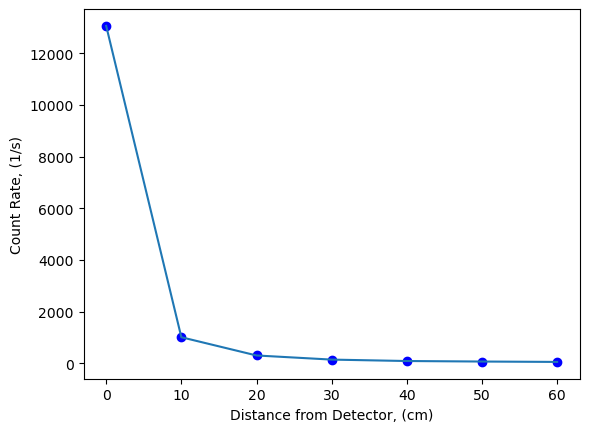

In [3]:
plt.scatter(distances, count_rates, color='blue')
plt.plot(distances, count_rates)
plt.xlabel("Distance from Detector, (cm)")
plt.ylabel("Count Rate, (1/s)")
plt.show()

The inverse-square law says that 

$$ R = \frac{a}{d^2}$$

Where $R$ is the rate, $d$ is the distance and $a$ is a proportionality constant.  One way to show whether your data follow this rule is to plot the logarithms of both sides of the equation, since

$$\log{R} = \log{(a/d^2)} = \log{a} - 2\log{d}$$

so if the rule is followed the result should be a line with a slope of &ndash;2.  Another way to show it would be to transform the $d$ values by transforming them into a list of $1/d^2$ values.  Again, the result, when plotted should be a line.  

Make one of these transformations, and plot the result.

In [4]:
# Convert to numpy arrays and remove zero distance
distances = np.array(distances[1:])  # now a numpy array
count_rates = np.array(count_rates[1:])

# Apply the inverse-square transformation
d_transform = 1 / distances**2

print("Transformed distances (1/d^2):", d_transform)
print("Count rates:", count_rates)

Transformed distances (1/d^2): [0.01       0.0025     0.00111111 0.000625   0.0004     0.00027778]
Count rates: [1006  300  140   85   65   50]


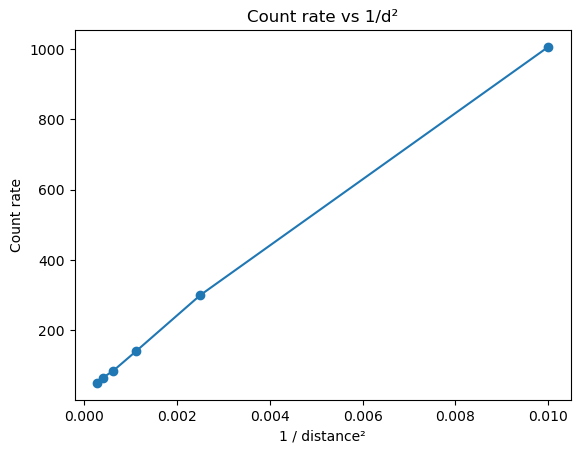

In [5]:
plt.scatter(d_transform, count_rates)
plt.plot(d_transform, count_rates)
plt.xlabel("1 / distance²")
plt.ylabel("Count rate")
plt.title("Count rate vs 1/d²")
plt.show()

### Fit the resulting linearized data

Use `polyfit()` and `poly1d()` from NumPy to fit your transformed data.  Check the slope and intercept to see if they make sense.  Plot the fit line over the data.  How does it look?

In [6]:
# First fit, and then print the coefficients
coefficients = np.polyfit(d_transform, count_rates, 1)  # degree 1 = linear
fit_line = np.poly1d(coefficients)

slope, intercept = coefficients
print(f"Slope: {slope:.2f}, Intercept: {intercept:.2f}")

Slope: 98071.91, Intercept: 30.56


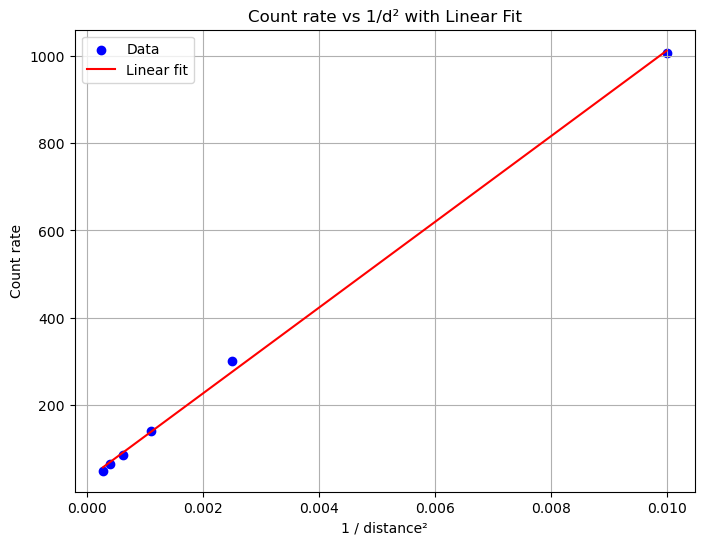

/home/jovyan/nuclear-electronics/Untitled Folder/Untitled Folder/timing-and-counting/timing-and-counting


In [7]:
# Then plot the fitline with the data.

plt.figure(figsize=(8, 6))
plt.scatter(d_transform, count_rates, color='blue', label='Data')
plt.plot(d_transform, fit_line(d_transform), color='red', label='Linear fit')
plt.xlabel("1 / distance²")
plt.ylabel("Count rate")
plt.title("Count rate vs 1/d² with Linear Fit")
plt.legend()
plt.grid(True)
plt.show()
import os
print(os.getcwd())

## Part 2: Exploring the count distribution from the interval distribution

This part may be challenging.  Expect to ask for help.

### Load the data file with the interval distribution

Use the `np.loadtxt()` function to load your data set of interval measurements into a numpy array.  Look up how this function is called with the **NumPy Reference** under the **Help** menu.  Store these values in an array called `intervals`.  (Note: The name `Interval_data.csv` will be the name of the data file used in the solution.)  

In [9]:
# You write all here (only need one line)
intervals_0_1 = np.loadtxt("0.1s Interval Time Raw Data Lab 2.txt", delimiter=",")
intervals_0_4 = np.loadtxt("0.4s Interval Time Raw Data Lab 2.txt", delimiter=",")
intervals_1 = np.loadtxt("1s Interval Time Raw Data Lab 2.txt", delimiter=",")

print("First 10 values (0.1 s):", intervals_0_1[:10])




First 10 values (0.1 s): [0.006907 0.000537 0.001018 0.000376 0.00658  0.001111 0.010047 0.003541
 0.001024 0.001878]


Make sure it worked by printing some values, the array size and a couple of statistics like the mean and variance.  Use `help(intervals)` to see the list of methods.  (**DO NOT PRINT the help text in your PDF that you upload for grading.**)

In [10]:
# help(intervals)
# DO NOT PRINT the help text in your PDF you upload for grading 
print("First 10 values (0.1 s):", intervals_0_1[:10])

First 10 values (0.1 s): [0.006907 0.000537 0.001018 0.000376 0.00658  0.001111 0.010047 0.003541
 0.001024 0.001878]


In [ ]:
# You write all here


### Make a histogram of the interval data

Make a histogram of the interval data with 50 bins.  Also look at it on a logarithmic axis.  What is the functional form that the distribution follows?  To set the axis scale to logarithmic, use, e.g., `plt.yscale('log')`.  Make sure to label your axes!

Text(0.5, 1.0, 'Histogram of 1s Interval Data (Linear scale)')

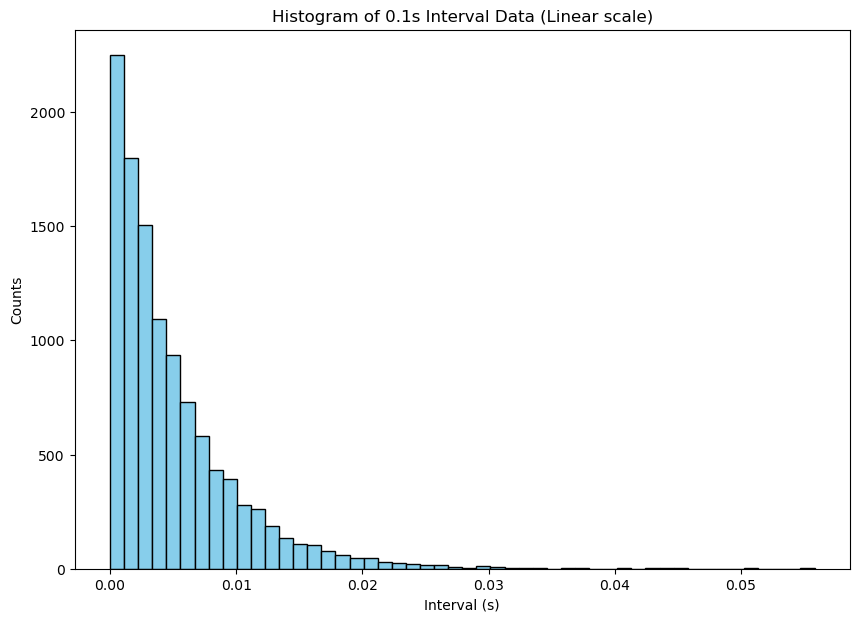

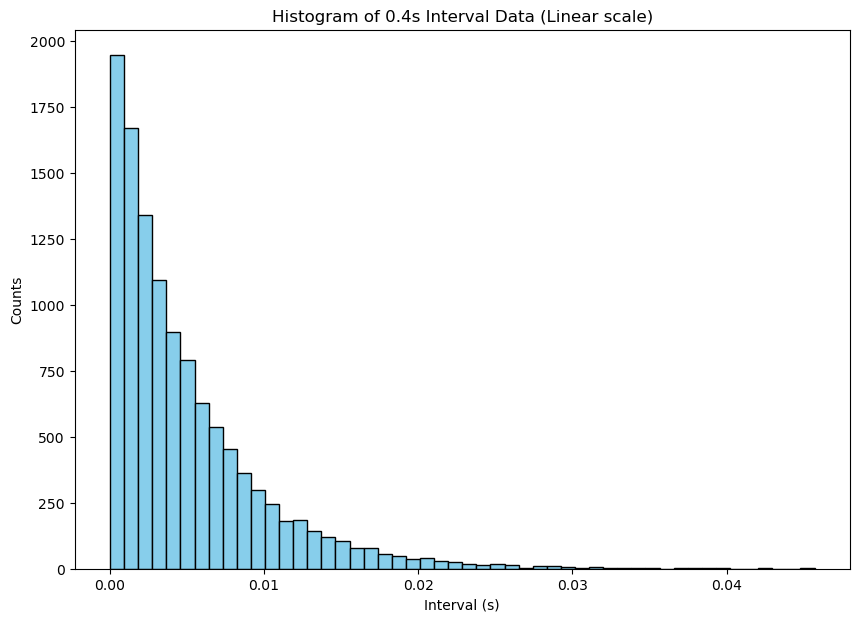

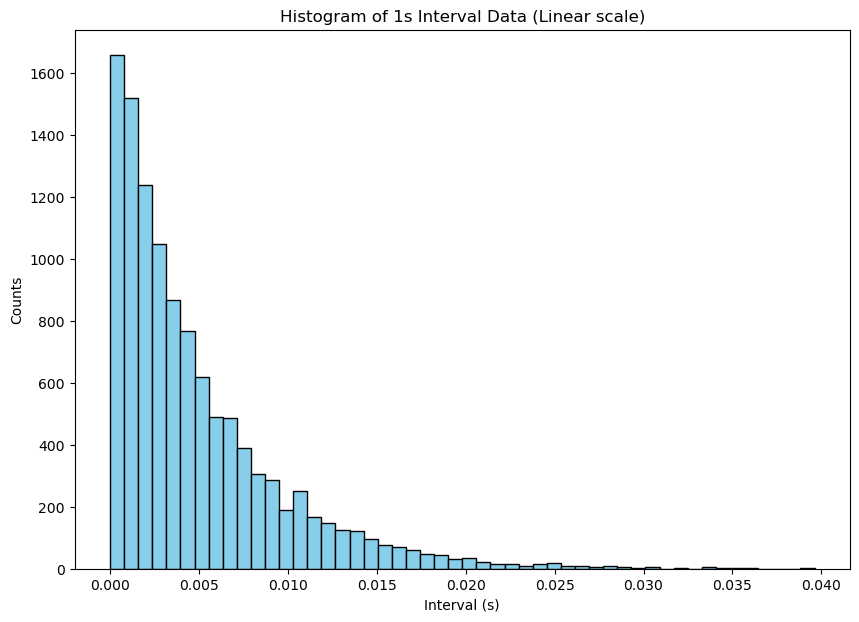

In [29]:
# First line makes the plot bigger 
plt.figure(figsize=(10,7))
# You fill in the rest
plt.hist(intervals_0_1, bins=50, color='skyblue', edgecolor='black')

plt.yscale('linear')


plt.xlabel("Interval (s)")
plt.ylabel("Counts")
plt.title("Histogram of 0.1s Interval Data (Linear scale)")


plt.figure(figsize=(10,7))
plt.hist(intervals_0_4, bins=50, color='skyblue', edgecolor='black')

plt.yscale('linear')


plt.xlabel("Interval (s)")
plt.ylabel("Counts")
plt.title("Histogram of 0.4s Interval Data (Linear scale)")


plt.figure(figsize=(10,7))
plt.hist(intervals_1, bins=50, color='skyblue', edgecolor='black')

plt.yscale('linear')


plt.xlabel("Interval (s)")
plt.ylabel("Counts")
plt.title("Histogram of 1s Interval Data (Linear scale)")




### Make a function that uses the interval distribution to make a count distribution

This is a little tricky.  The **interval** distribution is a list of (real, positive) numbers, each one representing the **time between successive pulses**.  Your goal is to create a new array of (positive) **integers** where each number corresponds to the number of counts in a succession of fixed-length intervals.  This would be called a **count** distribution.  

To make this, you need an algorithm. Imagine laying the interval distribution out along a time line.  The `*` represent a pulse at a particular time.  The interval distribution comes from the time between each `*`.  Then match it to a succession of fixed-length intervals. The fixed-length intervals are represented by the bar lines `|`:

`|       3       |       2       |       4       |       0       |       2       |       2       |        . . .`
`|-*----*------*-|------*-*------|-*--**-------*-|---------------|--*-*----------|--*------*-----|--*-*-- . . .`

The number of `*`s between each pair of bars represents the counts in each fixed-length interval.  For example, above, we see 3 counts in fixed-interval 1, 2 in fixed-interval 2, 4 in 3, 0 in 4, 2 in 5, etc. This list of integers would be the count distribution for the particular fixed-interval length.  You can see that if the fixed intervals were of a different length, the count distribution would also be different.

#### The algorithm

The algorithm (i.e., the logical procedure) that creates the count distribution would look like this: 

1. Set up two "partial sums": one for the sum of the intervals in the interval distribution, and the other for the sum of successive fixed intervals.  Call the first sum *intervalDistributionSum* and the other *fixedIntervalSum*.  Set *intervalDistributionSum* = 0 and *fixedIntervalSum* = fixed-interval-length to start.
2. Set up an array to hold the count distribution.
3. Set up a variable to hold the number of counts in a given fixed interval, e.g., *this_intervals_counts*.
4. Enter a `for` loop to interate over the elements in the interval distribution:
   1. Add the first interval in the interval distribution to *intervalDistributionSum*. 
   2. Is *intervalDistributionSum* less than *fixedIntervalSum*?  
      1. If so: Add 1 count to *this_intervals_counts*.
      2. If not, the current fixed interval is done, so 
         * Add the number in *this_intervals_counts* to the count distribution array in by appending it as an array element. 
         * Then reset *this_intervals_counts* to 1, because it will go into the next (or higher) interval. 
         * Finally, add a fixed-interval-length to *fixedIntervalSum*.
   3. Enter a `while` loop to add empty intervals to the count distribution array until *fixedIntervalSum* is greated than *intervalDistributionSum*:
      1. Increment *fixedIntervalSum* by a fixed-interval-length.
      2. append a 0 to the count distribution array.
   4. Once *fixedIntervalSum* is greater than *intervalDistributionSum*, continue with the next interval in the `for` loop by adding it to *intervalDistributionSum*.
5. Once the `for` loop is complete, return the count distribution array.  Note: The last fixed interval may be incomplete.  It should not be added to the array

In the code block below, the lines you need to write are indicated by `#### Write this line #####`. 

In [60]:
def make_count_dist(interval_dist, fixed_interval_length=1.0):
    # Set up count distribution array
    # Make it a zero-length array of "dtype=int"
    count_dist = np.zeros(0, dtype=int)
    
    # Initialize loop variables. You will need three:
    #     fixedIntervalSum : the partial sum of the fixed intervals up to a point
    #                        Initialize to the fixed_interval_length
    fixedIntervalSum = fixed_interval_length
    #     intervalDistributionSum : the partial sum of the intervals in the interval distribution up
    #                               to a point. Initialize to zero
    intervalDistributionSum = 0
    #     this_intervals_counts : The number of counts in the current fixed interval.
    #                             Initialize to zero
    this_intervals_counts = 0

    # Loop with each element in the interval distribution
    for interval in interval_dist:
        #  For each interval in interval_dist, add it to the sum of the previous intervals
        intervalDistributionSum += interval
 
        if (intervalDistributionSum <= fixedIntervalSum):
            # If the sum lies within the current fixed interval, then increment the counts in this interval
            this_intervals_counts += 1
        
        else:  # Otherwise, the intervalDistributionSum is above the fixed interval sum, so 
               # add the current counts to the count distribution
            count_dist = np.append(count_dist, this_intervals_counts)
            # Reset the interval counts to 1, since this count may go into the next interval
            this_intervals_counts = 1
            # Add the next fixed interval to the fixedIntervalSum
            fixedIntervalSum += fixed_interval_length
            # However, it may still be too small, so increment
            # the fixedIntervalSum and number of zero-count elements in count_dist
            # until the intervalDistributionSum is larger than the fixedIntervalSum.
            while (intervalDistributionSum > fixedIntervalSum):
                # increment the fixed interval sum
                fixedIntervalSum += fixed_interval_length
                # Add an empty interval to the array
                count_dist = np.append(count_dist, 0)     
        
        # Then go get the next interval from the interval_dist array
    # When all done, return the count distribution array
    return count_dist
    

### Test your function

Take a slice of, say, 100 values from the `intervals` array, and feed it to the function above.

Then calculate the length of the resulting count distribution, the sum of the number of counts in the distribution, and the mean and variance the distribution.  If your function works, the number of counts should be equal to the length of the slice, and the mean and variance should be about the same.  

Try your function with different fixed interval lengths, e.g., 0.02, 0.1, and 1 second.  What happens if the fixed interval length is greater than the sum of the intervals in the slice?

In [76]:
# Just execute this code block and consider the results

test_dist = intervals_0_1[0:100]
test_interval = .01 # seconds
counts_array = make_count_dist(test_dist,fixed_interval_length=test_interval)

# Looking at basic statistics.  For Poisson, mean should equal variance

print('Length of count distribution = {:d}' .format(len(counts_array)))
print('Number of counts = {:d}'.format(counts_array.sum()))
print('Mean = {:.4f}'.format(counts_array.mean()))
print('Variance = {:.4f}'.format(counts_array.var()))


Length of count distribution = 46
Number of counts = 99
Mean = 2.1522
Variance = 2.4334


#### Plot a histogram of the count distribution

Plot what you just calculated.  If it works, try your function on the whole data set.  Again, make sure to label your axes.

Recommended: make variable called `mybins` and set it to, say, 50.  Then pass the following arguments to the `plt.hist()` function: `bins=mybins, range=(0,mybins)`  This will make the x-axis behave in a sensible way.

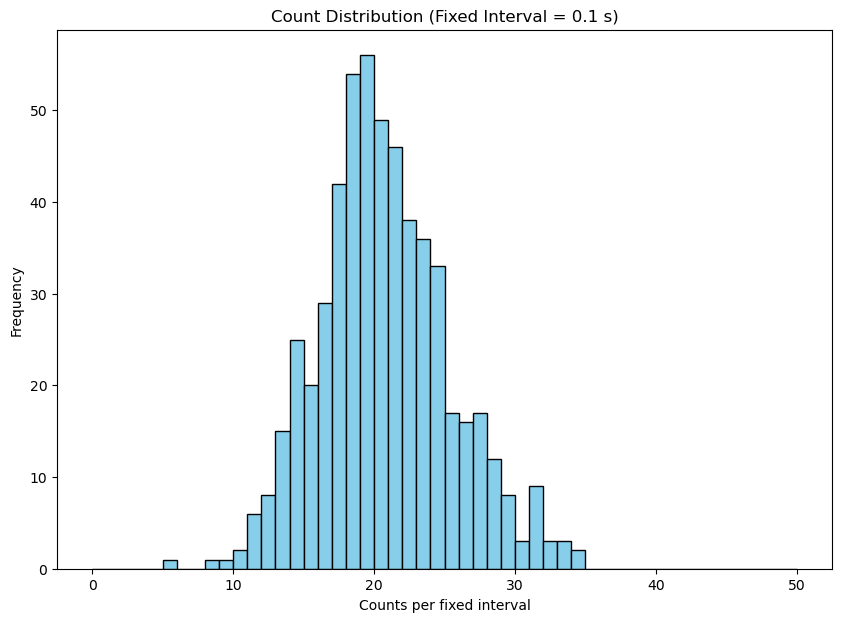

In [74]:
# Choose 50  bins for histogram
mybins = 50  

# Choose fixed interval length (seconds)
fixed_interval_length = 0.1  

# Generate the count distribution from the full dataset
counts_array = make_count_dist(intervals_0_1, fixed_interval_length=fixed_interval_length)

# Plot histogram
plt.figure(figsize=(10, 7))
plt.hist(counts_array, bins=mybins, range=(0, mybins), color='skyblue', edgecolor='black')

# Add labels and title
plt.xlabel("Counts per fixed interval")
plt.ylabel("Frequency")
plt.title(f"Count Distribution (Fixed Interval = {fixed_interval_length} s)")

plt.show()


### Compare the plot to a Poisson distribution

From `scipy.stats` import the `poisson()` function.  This is a function that will create a discrete Poisson distribution.  Look up the information under Help under **SciPy Reference**.  In particular, you will need to use the `poisson.pmf()` method to obtain a theoretical "curve". 

You will need to normalize the theoretical distribution to the size of the count distribution array.  Think about why this is true.

In [77]:
from scipy.stats import poisson

# make a function to return a theoretical distribution from the mean and size of the count distribution.
def poisson_theory(count_dist,bins):
    """
    Returns the theoretical Poisson distribution scaled to the histogram size.
    """
    
    # Calculate the mean of the experimental counts
    mean_count = count_dist.mean()
    
    # Set up k-values (integers) from 0 to bins
    k_values = np.arange(0, bins + 1)
    
    # Calculate Poisson probabilities
    poisson_probs = poisson.pmf(k_values, mu=mean_count)
    
    # Scale to match the size of the count distribution
    poisson_scaled = poisson_probs * len(count_dist)
    
    return k_values, poisson_scaled
    

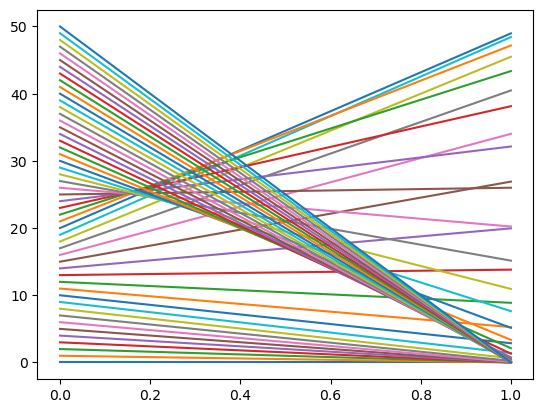

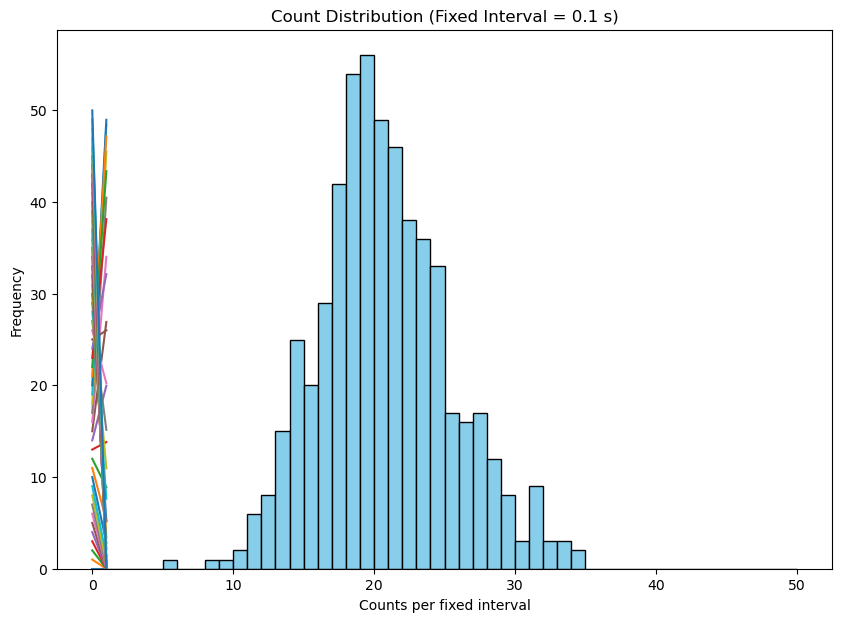

In [81]:
# Just copy what you used to make the the histogram above and add the line
# plt.plot(poisson_theory,'-') to overlay the theory, for example
# mybins = 50
# plt.plot(poisson_theory(counts_array, mybins),'-')

# You write rest


# Choose 50  bins for histogram
mybins = 50  
plt.plot(poisson_theory(counts_array, mybins),'-')
# Choose fixed interval length (seconds)
fixed_interval_length = 0.1  

# Generate the count distribution from the full dataset
counts_array = make_count_dist(intervals_0_1, fixed_interval_length=fixed_interval_length)

# Plot histogram
plt.figure(figsize=(10, 7))
plt.hist(counts_array, bins=mybins, range=(0, mybins), color='skyblue', edgecolor='black')


# Add labels and title
plt.xlabel("Counts per fixed interval")
plt.ylabel("Frequency")
plt.title(f"Count Distribution (Fixed Interval = {fixed_interval_length} s)")
plt.plot(poisson_theory(counts_array, mybins),'-')

plt.show()


### Plot histograms of three different count distributions on the same graph

Rerun the `make_count_dist()` function using three different fixed interval lengths and plot the results on the same graph in order to see how they evolve as the fixed interval changes.  (Add the theoretical distributions if you like.)


Keep the same number of bins and range for all, e.g., `mybins=60`.  Use the "kwargs" code from the previous analysis assignment to allow plots to overlap and still be visible.

In [ ]:
#plot histograms with different intervals

mybins = 60
kwargs = dict(bins=mybins, range=(0,mybins), alpha=0.5)
plt.figure(figsize=(10,7))
plt.xlabel('Counts in x s')
plt.ylabel('Frequency')
#
# Complete the rest of this block.  fixed interval lengths of .05, .15 and .30 s work well.

In [ ]:
# Fill in the arrays below.  delay_times will be the x-axis of the plot, delay_counts the y axis.

delay_times = np.array([], dtype=float)
delay_counts = np.array([], dtype=int)


## Part 3: The "Delay Curve"

This is easier than part 2.  You mostly just need to plot the delay-curve data in a sensible way. You can then use the computer to calculate a centroid.

Start by copying the delay curve data into the two numpy arrays.  **Note:** You need to set one of the delay time sets of data to a negative value, so that the delay of one counter to the other is a continuously-changing value.  In other words, if you delay detector 1 by 8ns relative to detector 2, then detector 2 is delayed by &ndash;8ns relative to detector 1.

In [ ]:
# Fill in the arrays below.  delay_times will be the x-axis of the plot, delay_counts the y axis.

delay_times = np.array([], dtype=float)
delay_counts = np.array([], dtype=int)

Then make a plot of the data.  Label the axes and title the graph.

In [ ]:
# You write all here

An easy centroid to calculate is a weighted average of the time data. With time in $x$ and counts in $y$ a formula for the centroid would be:

$$ x_\text{cent} = \frac{\sum x_iy_i}{\sum y_i}$$

If you know how numpy arrays handle element by element operations, you can write a function for the above in one line of code.

In [ ]:
# Write a function to calculate a centroid
# This assumes numpy arrays are used
def get_centroid(xdata,ydata):
    return #### You complete this line ####

# Apply it to obtain the center

best_delay = get_centroid(delay_times,delay_counts)
print('Optimal delay = {:.2f} ns'.format(best_delay))

### Plot the location of the centroid and estimate the width of the delay curve

Plot the position of the optimal delay time using the `plt.axvline(x)` function, where `x` is the position of a vertical line on the horizontal axis.  

Also turn on the plotting grid with `plt.grid()` to help estimate the width of the delay curve at half maximum.  How does this width compare to the widths of the discriminator outputs, which are about 10 ns each?

In [ ]:
# You write all here

#### Record your estimate in this Markdown cell:

Click on this cell and add your explanation of what you get for your optimal delay. FOR EXAMPLE:

<i>My estimate is from -X to +Y ns, or a width of Z ns.  This is almost double the width of the pulses, as expected because ...</i>
